<a href="https://colab.research.google.com/github/Farikah08/TaskMachineLearningWeek6/blob/main/naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes – Klasifikasi Survived pada Dataset Titanic
---


| No | Tahap |
|----|-------|
| 1 | Import library & dataset |
| 2 | Eksplorasi data |
| 3 | Preprocessing (imputasi, outlier IQR, encoding) |
| 4 | Split data (train & test) |
| 5 | Feature scaling |
| 6 | Training model Naive Bayes |
| 7 | Prediksi & evaluasi (confusion matrix, classification report) |

**Teorema Bayes:**  P(H|X) = P(X|H) · P(H) / P(X)


## Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## Importing the dataset


In [2]:
try:
    dataset = pd.read_csv('titanic.csv')
    print("Dataset dibaca dari file titanic.csv")
except FileNotFoundError:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    dataset = pd.read_csv(url)
    print("File lokal tidak ditemukan, dataset dibaca dari URL")

print("Shape:", dataset.shape)
dataset.head()

Dataset dibaca dari file titanic.csv
Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Eksplorasi Data

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
print("Missing value per kolom:")
miss = dataset.isnull().sum()
miss_df = pd.DataFrame({'Count': miss, 'Pct (%)': (miss / len(dataset) * 100).round(1)})
miss_df[miss_df['Count'] > 0].sort_values('Count', ascending=False)

Missing value per kolom:


,Count,Pct (%)
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Tidak selamat (0): 549 (61.6%)
Selamat (1)      : 342 (38.4%)


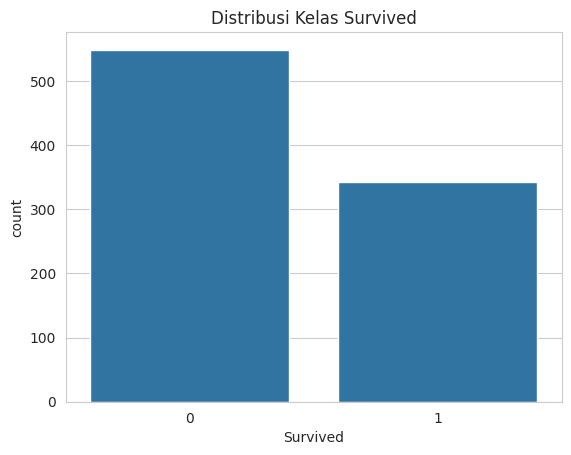

In [5]:
counts = dataset['Survived'].value_counts().sort_index()
print(f"Tidak selamat (0): {counts[0]} ({counts[0]/len(dataset)*100:.1f}%)")
print(f"Selamat (1)      : {counts[1]} ({counts[1]/len(dataset)*100:.1f}%)")

sns.countplot(x='Survived', data=dataset)
plt.title('Distribusi Kelas Survived')
plt.show()

## Preprocessing Data

### 1. Pilih fitur

In [6]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
target   = 'Survived'

df = dataset[features + [target]].copy()
df.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0


### 2. Imputasi missing value

In [7]:
median_age = df['Age'].median()
modus_emb  = df['Embarked'].mode()[0]

df['Age']      = df['Age'].fillna(median_age)
df['Embarked'] = df['Embarked'].fillna(modus_emb)

print(f"Median Age     = {median_age:.1f}")
print(f"Modus Embarked = '{modus_emb}'")
print()
print("Missing value setelah imputasi:")
print(df.isnull().sum())

Median Age     = 28.0
Modus Embarked = 'S'

Missing value setelah imputasi:
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
Survived    0
dtype: int64


### 3. Deteksi & penanganan outlier (IQR)

In [8]:
for col in ['Age', 'Fare']:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas  = Q3 + 1.5 * IQR
    n_out = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
    print(f"{col:5s} -> Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}, "
          f"batas=[{batas_bawah:.2f}, {batas_atas:.2f}], outlier={n_out}")

Age   -> Q1=22.00, Q3=35.00, IQR=13.00, batas=[2.50, 54.50], outlier=66
Fare  -> Q1=7.91, Q3=31.00, IQR=23.09, batas=[-26.72, 65.63], outlier=116


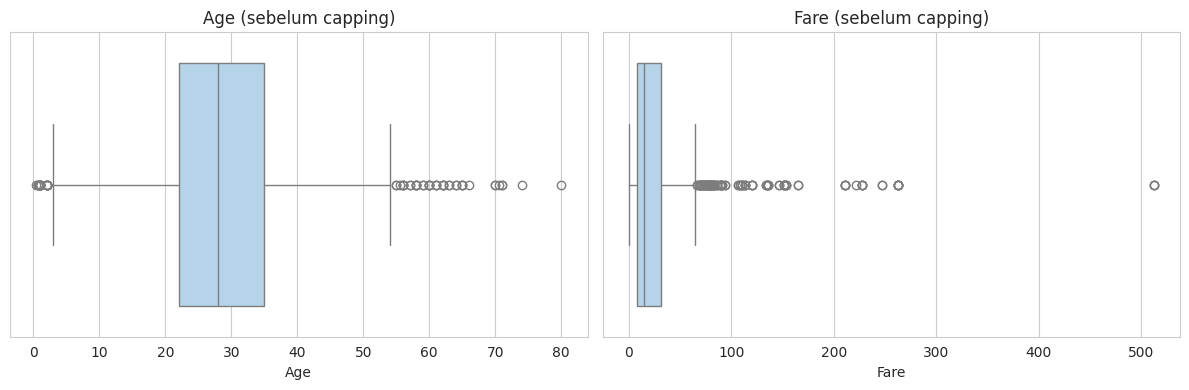

In [9]:
# Box plot sebelum capping
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Age', 'Fare']):
    sns.boxplot(x=df[col], ax=ax, color='#AED6F1')
    ax.set_title(f'{col} (sebelum capping)')
plt.tight_layout()
plt.show()

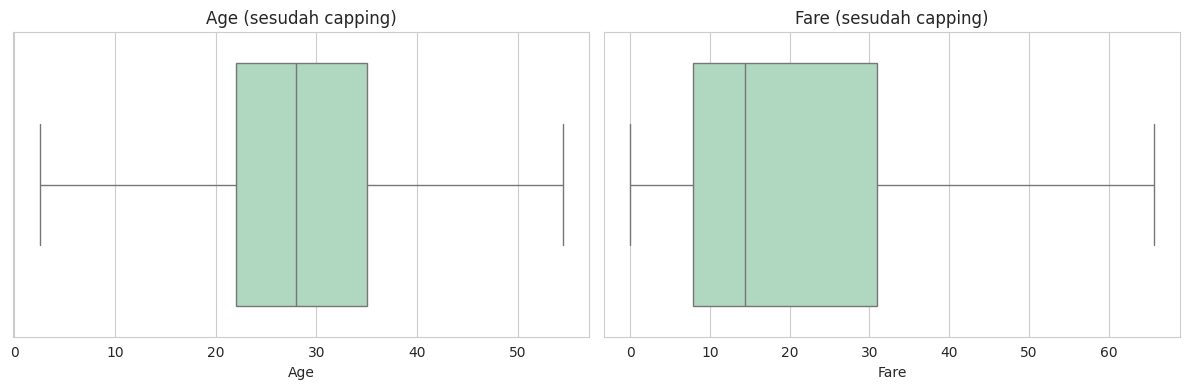

In [10]:
# Capping: nilai di luar batas IQR dipotong ke batas atas/bawah
for col in ['Age', 'Fare']:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)

# Box plot sesudah capping
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['Age', 'Fare']):
    sns.boxplot(x=df[col], ax=ax, color='#A9DFBF')
    ax.set_title(f'{col} (sesudah capping)')
plt.tight_layout()
plt.show()

### 4. Encoding data kategorikal

In [11]:
# Sex -> Label Encoding (female = 0, male = 1)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Sex'] = le.fit_transform(df['Sex'])
print("Mapping Sex:", {k: int(v) for k, v in zip(le.classes_, le.transform(le.classes_))})

# Embarked -> One-Hot Encoding
df = pd.get_dummies(df, columns=['Embarked'], prefix='Emb', dtype=int)

print("\nKolom setelah preprocessing:", df.columns.tolist())
print("Shape:", df.shape)
print("Total missing value:", df.isnull().sum().sum())
df.head()

Mapping Sex: {'female': 0, 'male': 1}

Kolom setelah preprocessing: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Survived', 'Emb_C', 'Emb_Q', 'Emb_S']
Shape: (891, 10)
Total missing value: 0


,Pclass,Sex,Age,SibSp,Parch,Fare,Survived,Emb_C,Emb_Q,Emb_S
0,3,1,22.0,1,0,7.2500,0,0,0,1
1,1,0,38.0,1,0,65.6344,1,1,0,0
2,3,0,26.0,0,0,7.9250,1,0,0,1
3,1,0,35.0,1,0,53.1000,1,0,0,1
4,3,1,35.0,0,0,8.0500,0,0,0,1


## Splitting the dataset into the Training set and Test set

In [12]:
X = df.drop(columns=target).values
y = df[target].values
feature_names = df.drop(columns=target).columns.tolist()

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print("Data latih:", X_train.shape)
print("Data uji  :", X_test.shape)
print("Proporsi Survived data latih:", np.bincount(y_train))
print("Proporsi Survived data uji  :", np.bincount(y_test))

Data latih: (712, 9)
Data uji  : (179, 9)
Proporsi Survived data latih: [439 273]
Proporsi Survived data uji  : [110  69]


## Feature Scaling

In [14]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [15]:
pd.DataFrame(X_train, columns=feature_names).head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Emb_C,Emb_Q,Emb_S
0,0.829568,0.742427,-0.095167,-0.465084,-0.466183,1.587890,-0.492527,-0.289333,0.611978
1,-0.370945,0.742427,-0.095167,-0.465084,-0.466183,-1.168968,-0.492527,-0.289333,0.611978
2,-1.571457,0.742427,-0.095167,-0.465084,-0.466183,2.033832,-0.492527,-0.289333,0.611978
3,0.829568,-1.346933,-0.921491,-0.465084,0.727782,-0.712711,-0.492527,-0.289333,0.611978
4,-0.370945,-1.346933,0.152731,0.478335,0.727782,0.111968,-0.492527,-0.289333,0.611978


## Training the Naive Bayes model on the Training set

In [16]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

In [17]:
print("Prior probability P(H) dari data latih:")
print(f"P(Survived=0) = {classifier.class_prior_[0]:.3f}")
print(f"P(Survived=1) = {classifier.class_prior_[1]:.3f}")

Prior probability P(H) dari data latih:
P(Survived=0) = 0.617
P(Survived=1) = 0.383


## Predicting the Test set results

In [18]:
y_pred = classifier.predict(X_test)

In [19]:
print(y_pred[:20])
print(y_test[:20])

[0 0 0 0 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1]
[0 0 1 0 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1]


## Making the Confusion Matrix

In [20]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
print("Akurasi:", round(accuracy_score(y_test, y_pred), 4))

[[89 21]
 [22 47]]
Akurasi: 0.7598


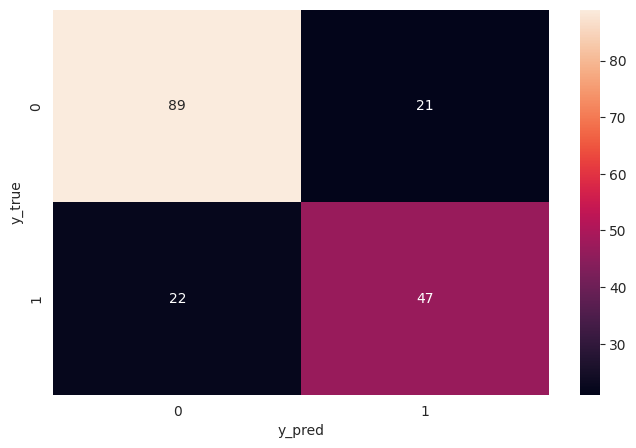

In [21]:
f, ax = plt.subplots(figsize=(8,5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt=".0f", ax=ax)
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()

In [22]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=['Tidak Selamat', 'Selamat']))

               precision    recall  f1-score   support

Tidak Selamat       0.80      0.81      0.81       110
      Selamat       0.69      0.68      0.69        69

     accuracy                           0.76       179
    macro avg       0.75      0.75      0.75       179
 weighted avg       0.76      0.76      0.76       179

